# 이미지 생성 베이스 모델 비교

가이드 기준(이미지 생성 퀄리티와 메모리 사용량 종합 고려)에 따라 후보 모델 13개를 같은 프롬프트 4개 × seed 3개로 생성하고, 다운로드 시간, 로드 시간, 워밍업 시간, 생성 시간, 피크 VRAM, 피크 RAM(로드 중·생성 중), 다운로드 용량을 측정한다.

- 측정값은 1장마다 `records.csv`에 바로 추가 저장한다. 커널이 종료되거나 다시 실행해도 이전 측정값이 남는다.
- 서비스는 게임마다 참조 이미지를 IP-Adapter로 넣어 그림체를 맞춘다. 그래서 텍스트 생성 측정이 끝난 모델마다 IP-Adapter 로드를 실제로 시도해 성공·실패를 `ipa_load.csv`에 기록한다. 이 시도는 별도 프로세스에서 실행해, 끝나면 메모리가 전부 반환되게 한다.
- IP-Adapter 기능이 없는 파이프라인(PixArt-Sigma, HunyuanDiT, Lumina2, CogView4, Z-Image)은 텍스트 생성만 측정하는 참고용으로 남긴다.

- 용도: 기능 B(배너), C(스타일 유지 홍보 이미지), F(굿즈 목업), D(굿즈 보존 배경)의 베이스 모델 선정
- 프롬프트: 애니풍 / 로우폴리 / 픽셀 / 굿즈 실물 사진
- 제외: FLUX.1-dev, SDXL-Turbo(비상업 라이선스), Sana(diffusers 파이프라인 클래스 미확인)

## 의존성 설치

In [1]:
# torch는 CUDA 빌드를 따로 설치해야 해서 여기서 설치하지 않음 (PyPI 기본은 Windows CPU 빌드)
%pip install -U transformers accelerate sentencepiece protobuf huggingface_hub matplotlib pandas
# Z-Image-Turbo 모델 카드에 diffusers를 소스로 설치하라고 되어 있어 git 버전 사용
%pip install -U git+https://github.com/huggingface/diffusers
%pip install --upgrade torch==2.14.1 torchvision torchaudio --index-url https://download.pytorch.org/whl/cu130

Note: you may need to restart the kernel to use updated packages.
  Cloning https://github.com/huggingface/diffusers to C:\Users\Administrator\AppData\Local\Temp\pip-req-build-g9rshm8d
  Resolved https://github.com/huggingface/diffusers to commit 4df4a5b35748bab1d967c0ff49ad1a144d094322
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
Note: you may need to restart the kernel to use updated packages.


  Running command git clone --filter=blob:none --quiet https://github.com/huggingface/diffusers 'C:\Users\Administrator\AppData\Local\Temp\pip-req-build-g9rshm8d'


Looking in indexes: https://download.pytorch.org/whl/cu130
Note: you may need to restart the kernel to use updated packages.


## 환경 확인

In [2]:
import torch
import torchvision
from diffusers import DiffusionPipeline

print('torch', torch.__version__, '| cuda', torch.cuda.is_available())
print('torchvision', torchvision.__version__)
print('diffusers import ok')

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Multiple distributions found for package optimum. Picked distribution: optimum
W1019 18:42:19.468000 44164 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1019 18:42:19.560000 44164 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading 

torch 2.14.1+cu130 | cuda True
torchvision 0.29.1+cu130
diffusers import ok


In [3]:
import torch

print('torch', torch.__version__)
print('cuda', torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print('gpu', p.name, f'{p.total_memory / 1024**3:.1f} GB')

torch 2.14.1+cu130
cuda True
gpu NVIDIA GeForce RTX 3090 24.0 GB


## Hugging Face 로그인

SD 3.5 Medium·Large·Large Turbo, FLUX.1-schnell은 모델 페이지에서 접근 동의 후 토큰으로 로그인해야 받을 수 있다.

In [4]:
from huggingface_hub import login

login()

## 비교 설정

In [7]:
from pathlib import Path

OUT_DIR = Path('../outputs/model_compare')
OUT_DIR.mkdir(parents=True, exist_ok=True)

# steps·cfg가 None이면 파이프라인 기본값 사용 (모델 카드에서 확인한 값만 지정)
# offload=True: 6B 이상이라 24GB에 전부 올리면 부족할 수 있는 모델
MODELS = {
    'sdxl_base':        dict(repo='stabilityai/stable-diffusion-xl-base-1.0', steps=None, cfg=None, offload=False),
    'animagine_xl4':    dict(repo='cagliostrolab/animagine-xl-4.0', steps=None, cfg=None, offload=False),
    'playground_v25':   dict(repo='playgroundai/playground-v2.5-1024px-aesthetic', steps=None, cfg=None, offload=False),
    'sd35_medium':      dict(repo='stabilityai/stable-diffusion-3.5-medium', steps=None, cfg=None, offload=False),
    'sd35_large':       dict(repo='stabilityai/stable-diffusion-3.5-large', steps=None, cfg=None, offload=True),
    'sd35_large_turbo': dict(repo='stabilityai/stable-diffusion-3.5-large-turbo', steps=4, cfg=0.0, offload=True),
    'flux1_schnell':    dict(repo='black-forest-labs/FLUX.1-schnell', steps=4, cfg=0.0, offload=True),
    'pixart_sigma':     dict(repo='PixArt-alpha/PixArt-Sigma-XL-2-1024-MS', steps=None, cfg=None, offload=False),
    # Kolors: offload 없이 생성 중 전용 23.6GB + 공유 2.6GB 사용 → VAE float32 디코딩 이후 3.13it/s → 344s/it로 느려짐. 다른 큰 모델과 같은 sequential 조건으로 비교
    'kolors':           dict(repo='Kwai-Kolors/Kolors-diffusers', steps=None, cfg=None, offload=True, variant='fp16', dtype='float16'),
    'hunyuan_dit_v12':  dict(repo='Tencent-Hunyuan/HunyuanDiT-v1.2-Diffusers', steps=None, cfg=None, offload=False),
    'lumina_image_2':   dict(repo='Alpha-VLLM/Lumina-Image-2.0', steps=None, cfg=None, offload=False),
    # CogView4 모델 카드 예제: CPU 오프로드 + VAE slicing·tiling을 같이 사용 (오프로드만 썼을 때 3회 연속 커널 종료)
    'cogview4_6b':      dict(repo='zai-org/CogView4-6B', steps=50, cfg=3.5, offload=True, vae_tiling=True),
     # Z-Image-Turbo: offload 없이 peak 21.67GB → Windows 공유 GPU 메모리로 넘쳐 스텝당 1.15s→738s로 느려짐. 다른 오프로드 모델과 같은 sequential 조건으로 비교
    'z_image_turbo':    dict(repo='Tongyi-MAI/Z-Image-Turbo', steps=9, cfg=0.0, offload=True),
}

# IP-Adapter 계열. 표에 없는 모델 = diffusers(efe46a5b) 파이프라인에 IP-Adapter 기능이 없음 → 텍스트 생성만 측정하는 참고용
# animagine·playground는 SDXL 계열 가중치로 시도 (SDXL 파이프라인으로 로드되는지는 '파이프라인 클래스 확인' 셀에서 확인)
IPA_FAMILY = {'sdxl_base': 'sdxl', 'animagine_xl4': 'sdxl', 'playground_v25': 'sdxl',
              'sd35_medium': 'sd3', 'sd35_large': 'sd3', 'sd35_large_turbo': 'sd3',
              'flux1_schnell': 'flux', 'kolors': 'kolors'}
for m, c in MODELS.items():
    c['ipa'] = IPA_FAMILY.get(m)

# 가중치는 diffusers(efe46a5b) 문서 예제에 있는 저장소만 사용. files = 로드 전에 받을 파일 (로드 시간에 다운로드가 섞이지 않게)
IPA = {
    # docs/source/en/using-diffusers/ip_adapter.md 51–54줄
    'sdxl': dict(repo='h94/IP-Adapter',
                 kwargs=dict(subfolder='sdxl_models', weight_name='ip-adapter_sdxl.bin'),
                 files=[('h94/IP-Adapter', ['sdxl_models/ip-adapter_sdxl.bin', 'sdxl_models/image_encoder/*'], None)]),
    # docs/source/en/api/pipelines/stable_diffusion/stable_diffusion_3.md 80–100줄 (이미지 인코더 SigLIP)
    # 문서 예제는 기본 파일명(ip-adapter.safetensors)을 쓰지만 저장소의 실제 파일은 ip-adapter.bin (10/19 저장소 목록 확인, 기본 파일명으로는 OSError)
    # image_encoder_folder에 '/'가 있으면 저장소 경로로 그대로 사용 (loaders/ip_adapter.py 1042–1045줄)
    'sd3': dict(repo='InstantX/SD3.5-Large-IP-Adapter',
                kwargs=dict(weight_name='ip-adapter.bin', image_encoder_folder='google/siglip-so400m-patch14-384'),
                files=[('InstantX/SD3.5-Large-IP-Adapter', ['ip-adapter.bin'], None),
                       ('google/siglip-so400m-patch14-384', ['*.json', '*.safetensors', '*.model', '*.txt'], None)]),
    # docs/source/en/api/pipelines/flux.md 436–440줄 (문서 예제는 FLUX.1-dev 기준)
    'flux': dict(repo='XLabs-AI/flux-ip-adapter',
                 kwargs=dict(weight_name='ip_adapter.safetensors', image_encoder_pretrained_model_name_or_path='openai/clip-vit-large-patch14'),
                 files=[('XLabs-AI/flux-ip-adapter', ['ip_adapter.safetensors'], None),
                        ('openai/clip-vit-large-patch14', ['*.json', '*.safetensors', '*.txt'], None)]),
    # docs/source/en/api/pipelines/kolors.md 60–85줄: 이미지 인코더를 refs/pr/4에서 따로 로드 후 image_encoder_folder=None
    # (IPAdapterMixin이 이미지 인코더를 직접 받을 때는 revision을 넘기지 않음, loaders/ip_adapter.py 214–220줄)
    'kolors': dict(repo='Kwai-Kolors/Kolors-IP-Adapter-Plus',
                   kwargs=dict(subfolder='', weight_name='ip_adapter_plus_general.safetensors', revision='refs/pr/4', image_encoder_folder=None),
                   image_encoder=dict(subfolder='image_encoder', revision='refs/pr/4'),
                   files=[('Kwai-Kolors/Kolors-IP-Adapter-Plus', ['ip_adapter_plus_general.safetensors', 'image_encoder/*'], 'refs/pr/4')]),
}

PROMPTS = {
    'anime': 'black cat adventurer standing upright, red wide-brim hat, olive green cape, walking along a dirt road through green fields, flat color, cel shading, clean thin lineart, storybook fantasy',
    'lowpoly': 'low poly 3d game render, small knight character in a village square, flat shaded polygons, isometric view, bright colors',
    'pixel': 'pixel art, 16-bit dungeon room, small knight character, top-down view, limited color palette',
    'product': 'product photo of a plain white t-shirt with a small black cat print, on a wooden table, soft studio lighting, realistic',
}
# 값 자체는 의미 없음. 1장으로는 그 seed에서 우연히 잘·못 나온 결과와 모델 차이를 구분할 수 없어 프롬프트당 3장 생성
SEEDS = [0, 1, 2]

## 파이프라인 클래스 확인

IP-Adapter 기능은 파이프라인 클래스에 따라 있고 없다. 각 저장소의 `model_index.json`(수 KB)만 받아 실제로 로드될 클래스를 확인한다. 모델 본체는 받지 않는다.

In [8]:
from diffusers import DiffusionPipeline

for m, c in MODELS.items():
    try:
        print(f"{m:16s} {DiffusionPipeline.load_config(c['repo'])['_class_name']:32s} ipa={c['ipa']}")
    except Exception as e:
        print(f'{m:16s} 실패: {e}')

sdxl_base        StableDiffusionXLPipeline        ipa=sdxl
animagine_xl4    StableDiffusionXLPipeline        ipa=sdxl
playground_v25   StableDiffusionXLPipeline        ipa=sdxl
sd35_medium      StableDiffusion3Pipeline         ipa=sd3
sd35_large       StableDiffusion3Pipeline         ipa=sd3
sd35_large_turbo StableDiffusion3Pipeline         ipa=sd3
flux1_schnell    FluxPipeline                     ipa=flux
pixart_sigma     PixArtSigmaPipeline              ipa=None


c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Administrator\.cache\huggingface\hub\models--Kwai-Kolors--Kolors-diffusers. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


kolors           KolorsPipeline                   ipa=kolors
hunyuan_dit_v12  HunyuanDiTPipeline               ipa=None
lumina_image_2   Lumina2Pipeline                  ipa=None
cogview4_6b      CogView4Pipeline                 ipa=None
z_image_turbo    ZImagePipeline                   ipa=None


## 디스크 확인

13개 모델 저장소 용량 합계가 약 589GB라, 모델 1개를 받아 측정한 뒤 캐시에서 바로 삭제하고 다음 모델로 넘어간다. 디스크에는 한 번에 모델 1개만 남는다.

In [9]:
import shutil

from huggingface_hub import scan_cache_dir
from huggingface_hub.constants import HF_HUB_CACHE

def free_gb():
    return shutil.disk_usage(HF_HUB_CACHE).free / 1024**3

def cached_repo(repo_id):
    return next((r for r in scan_cache_dir().repos if r.repo_id == repo_id), None)

def delete_cached(repo_id):
    r = cached_repo(repo_id)
    if r is None:
        return 0.0
    size = r.size_on_disk / 1024**3
    scan_cache_dir().delete_revisions(*[rev.commit_hash for rev in r.revisions]).execute()
    return size

print('HF cache:', HF_HUB_CACHE)
print(f'free: {free_gb():.1f} GB')
# 저장소 용량 기준 가장 큰 모델(SDXL base 77.4GB)보다 여유가 적으면 중간에 디스크가 찰 수 있음
assert free_gb() > 80, '디스크 여유 공간이 80GB 미만'

HF cache: C:\Users\Administrator\.cache\huggingface\hub
free: 172.2 GB


Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Administrator\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading pipeline components...: 100%|██████████| 5/5 [00:08<00:00,  

vae               0.16 GB
text_encoder     11.63 GB
unet              4.80 GB
GPU에 올린 직후 allocated 16.72 GB / 전체 24.0 GB, 남은 여유 7.28 GB


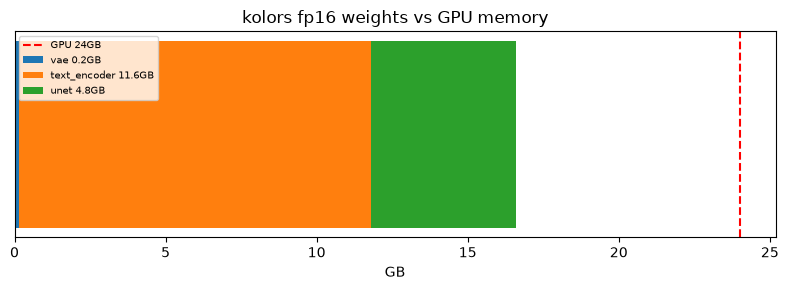

In [10]:
import torch
import matplotlib.pyplot as plt
from diffusers import DiffusionPipeline

cfg = MODELS['kolors']
pipe = DiffusionPipeline.from_pretrained(cfg['repo'], torch_dtype=torch.float16, variant='fp16')
sizes = {n: sum(p.numel() * p.element_size() for p in m.parameters()) / 1024**3
         for n, m in pipe.components.items() if isinstance(m, torch.nn.Module)}
for n, gb in sizes.items():
    print(f'{n:15s} {gb:6.2f} GB')
pipe.to('cuda')
torch.cuda.synchronize()
alloc = torch.cuda.memory_allocated() / 1024**3
total = torch.cuda.get_device_properties(0).total_memory / 1024**3
print(f'GPU에 올린 직후 allocated {alloc:.2f} GB / 전체 {total:.1f} GB, 남은 여유 {total - alloc:.2f} GB')

fig, ax = plt.subplots(figsize=(8, 3))
left = 0
for n, gb in sizes.items():
    ax.barh(0, gb, left=left, label=f'{n} {gb:.1f}GB')
    left += gb
ax.axvline(total, color='red', linestyle='--', label=f'GPU {total:.0f}GB')
ax.set_yticks([])
ax.set_xlabel('GB')
ax.legend(fontsize=7, loc='upper left')
ax.set_title('kolors fp16 weights vs GPU memory')
plt.tight_layout()
plt.show()

del pipe
torch.cuda.empty_cache()

드라이버 기준 GPU 사용 1.21 GB / 24.0 GB
이 커널 allocated 0.00 GB, reserved 0.00 GB
이 커널 밖(다른 프로세스·CUDA 컨텍스트 등) 1.21 GB


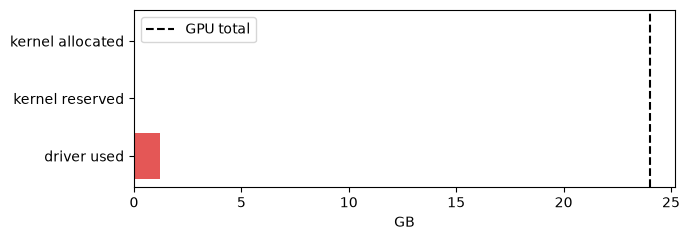

In [11]:
import torch
import matplotlib.pyplot as plt

free, total = torch.cuda.mem_get_info()
driver_used = (total - free) / 1024**3
alloc = torch.cuda.memory_allocated() / 1024**3
reserved = torch.cuda.memory_reserved() / 1024**3
print(f'드라이버 기준 GPU 사용 {driver_used:.2f} GB / {total/1024**3:.1f} GB')
print(f'이 커널 allocated {alloc:.2f} GB, reserved {reserved:.2f} GB')
print(f'이 커널 밖(다른 프로세스·CUDA 컨텍스트 등) {driver_used - reserved:.2f} GB')

fig, ax = plt.subplots(figsize=(7, 2.5))
ax.barh(['driver used', 'kernel reserved', 'kernel allocated'], [driver_used, reserved, alloc], color=['#E45756', '#F58518', '#4C78A8'])
ax.axvline(total / 1024**3, color='black', linestyle='--', label='GPU total')
ax.set_xlabel('GB')
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
from huggingface_hub import whoami, auth_check
from huggingface_hub.errors import GatedRepoError, RepositoryNotFoundError

print('token user:', whoami()['name'])
for repo in ['stabilityai/stable-diffusion-3.5-medium',
             'stabilityai/stable-diffusion-3.5-large',
             'stabilityai/stable-diffusion-3.5-large-turbo',
             'black-forest-labs/FLUX.1-schnell',
             *sorted({r for spec in IPA.values() for r, _, _ in spec['files']})]:
    try:
        auth_check(repo)
        print(f'OK      {repo}')
    except GatedRepoError:
        print(f'GATED   {repo}')
    except RepositoryNotFoundError:
        print(f'NOTFOUND {repo}')

token user: beepcon
OK      stabilityai/stable-diffusion-3.5-medium
OK      stabilityai/stable-diffusion-3.5-large
OK      stabilityai/stable-diffusion-3.5-large-turbo
OK      black-forest-labs/FLUX.1-schnell
OK      InstantX/SD3.5-Large-IP-Adapter
OK      Kwai-Kolors/Kolors-IP-Adapter-Plus
OK      XLabs-AI/flux-ip-adapter
OK      google/siglip-so400m-patch14-384
OK      h94/IP-Adapter
OK      openai/clip-vit-large-patch14


## 생성 및 측정

In [13]:
import gc
import json
import os
import subprocess
import sys
import threading
import time

from diffusers import DiffusionPipeline
from huggingface_hub import snapshot_download
import pandas as pd
import psutil
from PIL import Image

# 1장마다 바로 CSV에 추가 → 커널 종료·재실행에도 측정값이 남음
RECORDS_CSV = OUT_DIR / 'records.csv'
records = pd.read_csv(RECORDS_CSV).to_dict('records') if RECORDS_CSV.exists() else []
images = {}
errors = {}
disk_log = []
new_count = 0


IPA_CSV = OUT_DIR / 'ipa_load.csv'
ipa_records = pd.read_csv(IPA_CSV).to_dict('records') if IPA_CSV.exists() else []


def save_record(rec):
    records.append(rec)
    pd.DataFrame([rec]).to_csv(RECORDS_CSV, mode='a', header=not RECORDS_CSV.exists(), index=False, encoding='utf-8')


class PeakRAM:
    # 직전 값만으로는 오프로드 모델이 CPU RAM에 올리는 가중치 크기를 알 수 없어 구간 중 최댓값을 샘플링
    def __init__(self, interval=0.2):
        self.proc = psutil.Process()
        self.interval = interval
        self._stop = threading.Event()

    def _run(self):
        while not self._stop.wait(self.interval):
            self.peak = max(self.peak, self.proc.memory_info().rss)

    def __enter__(self):
        self.peak = self.proc.memory_info().rss
        self._t = threading.Thread(target=self._run, daemon=True)
        self._t.start()
        return self

    def __exit__(self, *exc):
        self._stop.set()
        self._t.join()

    @property
    def gb(self):
        return round(self.peak / 1024**3, 2)


def make_kwargs(cfg, prompt, seed):
    kwargs = dict(prompt=prompt, width=1024, height=1024,
                  generator=torch.Generator('cpu').manual_seed(seed))
    if cfg['steps'] is not None:
        kwargs['num_inference_steps'] = cfg['steps']
    if cfg['cfg'] is not None:
        kwargs['guidance_scale'] = cfg['cfg']
    return kwargs


# 별도 프로세스에서 실행할 IP-Adapter 로드 코드. 입력은 stdin JSON, 결과는 'IPA_RESULT {json}' 한 줄로 출력
IPA_CHILD = r"""
import json, sys, threading, time
import psutil, torch
from diffusers import DiffusionPipeline
from transformers import CLIPVisionModelWithProjection

a = json.loads(sys.stdin.read())
proc = psutil.Process()
peak = [proc.memory_info().rss]
stop = threading.Event()


def watch():
    while not stop.wait(0.2):
        peak[0] = max(peak[0], proc.memory_info().rss)


threading.Thread(target=watch, daemon=True).start()
out = {'pipeline': None, 'ok': False, 'error': '', 'ipa_load_sec': None}
try:
    kw = {'torch_dtype': getattr(torch, a['dtype'])}
    if a['variant']:
        kw['variant'] = a['variant']
    pipe = DiffusionPipeline.from_pretrained(a['repo'], **kw)
    out['pipeline'] = type(pipe).__name__
    t0 = time.perf_counter()
    if a['image_encoder']:
        pipe.register_modules(image_encoder=CLIPVisionModelWithProjection.from_pretrained(
            a['ipa_repo'], dtype=pipe.dtype, low_cpu_mem_usage=True, **a['image_encoder']))
    pipe.load_ip_adapter(a['ipa_repo'], **a['kwargs'])
    out['ipa_load_sec'] = round(time.perf_counter() - t0, 2)
    out['ok'] = True
except Exception as e:
    out['error'] = f'{type(e).__name__}: {e}'[:500]
stop.set()
out['peak_ram_gb'] = round(peak[0] / 1024**3, 2)
print('IPA_RESULT ' + json.dumps(out), flush=True)
"""


def ram_log(name, tag):
    # 커널 종료 원인 확인용: 단계 사이에 메모리가 반환되는지 숫자로 남김 (10/19 14:07 로그: IP-Adapter 시도 직후 FLUX 로드 중 커널 종료)
    vm, sw = psutil.virtual_memory(), psutil.swap_memory()
    print(f'{name:16s} [RAM {tag:15s}] avail={vm.available/1024**3:5.1f}GB used={vm.percent:4.1f}% '
          f'swap used={sw.used/1024**3:5.1f}/{sw.total/1024**3:5.1f}GB proc={psutil.Process().memory_info().rss/1024**3:5.1f}GB', flush=True)


def ipa_test(name, cfg):
    spec = IPA[cfg['ipa']]
    rec = {'model': name, 'ipa': cfg['ipa'], 'ipa_repo': spec['repo'], 'pipeline': None, 'ok': False, 'error': '',
           'ipa_download_sec': None, 'ipa_load_sec': None, 'peak_ram_gb': None}
    try:
        t0 = time.perf_counter()
        for repo, patterns, rev in spec['files']:
            snapshot_download(repo, allow_patterns=patterns, revision=rev)
        rec['ipa_download_sec'] = round(time.perf_counter() - t0, 2)
        # IP-Adapter 로더는 LoRA 로더와 달리 오프로드 훅을 풀지 않음(loaders/ip_adapter.py에 offload 처리 없음, lora_base.py 409줄과 대비)
        # → 오프로드 없이 CPU에 새로 로드해서 시도. 커널과 다른 프로세스라 끝나면 OS가 메모리를 전부 회수하고, 메모리 부족으로 죽어도 커널은 남음
        arg = json.dumps({'repo': cfg['repo'], 'dtype': cfg.get('dtype', 'bfloat16'), 'variant': cfg.get('variant'),
                          'ipa_repo': spec['repo'], 'kwargs': spec['kwargs'], 'image_encoder': spec.get('image_encoder')})
        p = subprocess.run([sys.executable, '-c', IPA_CHILD], input=arg, capture_output=True, text=True,
                           encoding='utf-8', errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
        line = next((l for l in p.stdout.splitlines() if l.startswith('IPA_RESULT ')), None)
        if line is None:
            rec['error'] = f'child exit {p.returncode}: {p.stderr[-400:]}'
        else:
            rec.update(json.loads(line[len('IPA_RESULT '):]))
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:500]
    ipa_records.append(rec)
    pd.DataFrame([rec]).to_csv(IPA_CSV, mode='a', header=not IPA_CSV.exists(), index=False, encoding='utf-8')
    print(f"{name:16s} IP-Adapter {'OK  ' if rec['ok'] else 'FAIL'} {rec['pipeline']} download={rec['ipa_download_sec']}s "
          f"load={rec['ipa_load_sec']}s peak_ram={rec['peak_ram_gb']}GB {rec['error'][:150]}", flush=True)


# PNG만 있고 측정 기록이 없으면 다시 측정 (PNG 기준으로 건너뛰어 측정값이 빠졌던 문제)
def png_path(m, p, s):
    return OUT_DIR / f'{m}_{p}_s{s}.png'


recorded = {(r['model'], r['prompt'], r['seed']) for r in records}
DONE = {m for m in MODELS if all((m, p, s) in recorded and png_path(m, p, s).exists() for p in PROMPTS for s in SEEDS)}
IPA_DONE = {r['model'] for r in ipa_records}
print('skip:', sorted(DONE), '| IP-Adapter skip:', sorted(IPA_DONE))
for name, cfg in MODELS.items():
    need_text = name not in DONE
    need_ipa = cfg['ipa'] is not None and name not in IPA_DONE
    if not need_text:
        for pname in PROMPTS:
            for seed in SEEDS:
                images[(name, pname, seed)] = Image.open(png_path(name, pname, seed))
    if not (need_text or need_ipa):
        continue
    pipe = None
    download_gb = None
    # CogView4 모델 카드: fp16은 오버플로로 검은 이미지가 나와 bf16 사용, 3090은 bf16 지원이라 전 모델 통일
    load_kwargs = dict(torch_dtype=getattr(torch, cfg.get('dtype', 'bfloat16')))
    if cfg.get('variant'):
        load_kwargs['variant'] = cfg['variant']
    ram_log(name, 'before load')
    try:
        # 다운로드를 먼저 끝내야 로드 시간에 네트워크 시간이 섞이지 않음 (from_pretrained도 내부에서 같은 download를 호출)
        t0 = time.perf_counter()
        DiffusionPipeline.download(cfg['repo'], variant=cfg.get('variant'))
        download_sec = round(time.perf_counter() - t0, 2)
        r = cached_repo(cfg['repo'])
        download_gb = round(r.size_on_disk / 1024**3, 2) if r else None

        if need_text:
            with PeakRAM() as load_ram:
                t0 = time.perf_counter()
                pipe = DiffusionPipeline.from_pretrained(cfg['repo'], **load_kwargs)
                if cfg['offload']:
                    # enable_model_cpu_offload 사용 시 CogView4·SD3.5 Large가 RAM 여유(26.9GB)가 있는데도 커널 종료 → 모듈 단위로 옮기는 sequential 방식으로 변경 (느림)
                    pipe.enable_sequential_cpu_offload()
                else:
                    pipe.to('cuda')
                if cfg.get('vae_tiling'):
                    pipe.vae.enable_slicing()
                    pipe.vae.enable_tiling()
                load_sec = round(time.perf_counter() - t0, 2)
            print(f'{name:16s} download={download_sec:7.1f}s ({download_gb}GB) load={load_sec:6.1f}s load_peak_ram={load_ram.gb:5.2f}GB', flush=True)

            # 첫 생성은 초기화 시간이 섞여 느림(FLUX 첫 장 41.5s, 나머지 26.9~27.6s) → 기록용과 별도로 1장 먼저 생성하고 시간만 기록
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            pipe(**make_kwargs(cfg, next(iter(PROMPTS.values())), SEEDS[0]))
            torch.cuda.synchronize()
            warmup_sec = round(time.perf_counter() - t0, 2)
            print(f'{name:16s} warmup   time={warmup_sec:6.1f}s', flush=True)

            for pname, prompt in PROMPTS.items():
                for seed in SEEDS:
                    # 커널 종료 원인 확인용: 생성 직전 시스템 RAM 상태를 출력 (flush로 크래시 전에 화면에 남김)
                    vm, sw = psutil.virtual_memory(), psutil.swap_memory()
                    print(f'{name:16s} {pname:8s} s{seed} RAM avail={vm.available/1024**3:5.1f}GB used={vm.percent:4.1f}% '
                          f'swap used={sw.used/1024**3:5.1f}/{sw.total/1024**3:5.1f}GB proc={psutil.Process().memory_info().rss/1024**3:5.1f}GB', flush=True)
                    try:
                        torch.cuda.reset_peak_memory_stats()
                        torch.cuda.synchronize()
                        with PeakRAM() as gen_ram:
                            t0 = time.perf_counter()
                            img = pipe(**make_kwargs(cfg, prompt, seed)).images[0]
                            torch.cuda.synchronize()
                            sec = time.perf_counter() - t0
                        vram = torch.cuda.max_memory_allocated() / 1024**3
                    except Exception as e:
                        errors[f'{name}/{pname}/s{seed}'] = f'gen: {e}'
                        print(f'{name:16s} {pname:8s} s{seed} GEN FAIL: {e}')
                        continue
                    img.save(png_path(name, pname, seed))
                    images[(name, pname, seed)] = img
                    save_record({'model': name, 'prompt': pname, 'seed': seed, 'offload': cfg['offload'],
                                 'sec': round(sec, 2), 'peak_vram_gb': round(vram, 2), 'peak_ram_gb': gen_ram.gb,
                                 'warmup_sec': warmup_sec, 'load_sec': load_sec, 'load_peak_ram_gb': load_ram.gb,
                                 'download_sec': download_sec, 'download_gb': download_gb})
                    new_count += 1
                    print(f'{name:16s} {pname:8s} s{seed} time={sec:6.1f}s peak_vram={vram:5.2f}GB peak_ram={gen_ram.gb:5.2f}GB', flush=True)
    except Exception as e:
        errors[name] = f'load: {e}'
        print(f'{name:16s} LOAD FAIL: {e}')
    finally:
        del pipe
        gc.collect()
        torch.cuda.empty_cache()
        ram_log(name, 'after cleanup')
        # 텍스트 생성 측정 조건을 IP-Adapter 없는 상태로 유지하려고 측정이 끝난 뒤 따로 시도. 모델 캐시를 지우기 전에 해야 다시 받지 않음
        if need_ipa:
            ipa_test(name, cfg)
            ram_log(name, 'after IP-Adapter')
        deleted = delete_cached(cfg['repo'])
        disk_log.append({'model': name, 'download_gb': download_gb, 'deleted_gb': round(deleted, 2), 'free_gb_after': round(free_gb(), 1)})
        print(f'{name:16s} cache deleted {deleted:.1f} GB, free {free_gb():.1f} GB')

print(f'이번 실행 {new_count}장 기록 / 실패 {len(errors)}건 / records.csv 누적 {len(records)}줄 / ipa_load.csv 누적 {len(ipa_records)}줄')
for k, v in errors.items():
    print('FAIL', k, v[:200])

skip: ['animagine_xl4', 'flux1_schnell', 'pixart_sigma', 'playground_v25', 'sd35_large', 'sd35_large_turbo', 'sd35_medium', 'sdxl_base'] | IP-Adapter skip: ['animagine_xl4', 'flux1_schnell', 'playground_v25', 'sd35_large', 'sd35_large_turbo', 'sd35_medium', 'sdxl_base']
kolors           [RAM before load    ] avail= 39.0GB used=39.0% swap used=  2.7/ 19.7GB proc=  1.1GB


c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...: 100%|██████████| 5/5 [00:08<00:00,  1.78s/it]

kolors           download=    0.4s (16.59GB) load=   9.5s load_peak_ram=13.28GB



[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!
100%|██████████| 50/50 [01:42<00:00,  2.04s/it]
c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\diffusers\pipelines\kolors\pipeline_kolors.py:582: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


kolors           warmup   time= 108.5s
kolors           anime    s0 RAM avail= 22.0GB used=65.5% swap used=  2.7/ 28.8GB proc= 18.6GB


100%|██████████| 50/50 [01:39<00:00,  1.99s/it]
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


... (133 outputs left out)

100%|██████████| 9/9 [00:37<00:00,  4.16s/it]


z_image_turbo    product  s1 time=  39.9s peak_vram= 2.39GB peak_ram=22.06GB
z_image_turbo    product  s2 RAM avail= 21.6GB used=66.2% swap used=  2.6/ 23.0GB proc= 22.0GB


100%|██████████| 9/9 [00:37<00:00,  4.18s/it]


z_image_turbo    product  s2 time=  40.1s peak_vram= 2.39GB peak_ram=22.05GB
z_image_turbo    [RAM after cleanup  ] avail= 29.2GB used=54.2% swap used=  2.6/ 22.6GB proc= 14.4GB
z_image_turbo    cache deleted 30.6 GB, free 168.6 GB
이번 실행 60장 기록 / 실패 0건 / records.csv 누적 156줄 / ipa_load.csv 누적 8줄


## 결과 표

In [14]:
import pandas as pd

# 같은 모델을 다시 측정하면 마지막 측정값만 사용
df = pd.DataFrame(records).drop_duplicates(['model', 'prompt', 'seed'], keep='last')
df.to_csv(OUT_DIR / 'compare_results.csv', index=False, encoding='utf-8-sig')
disk_df = pd.DataFrame(disk_log)
disk_df.to_csv(OUT_DIR / 'disk_log.csv', index=False, encoding='utf-8-sig')
summary = df.groupby('model', sort=False).agg(
    offload=('offload', 'first'),
    avg_sec=('sec', 'mean'),
    std_sec=('sec', 'std'),
    warmup_sec=('warmup_sec', 'first'),
    load_sec=('load_sec', 'first'),
    max_vram_gb=('peak_vram_gb', 'max'),
    max_ram_gb=('peak_ram_gb', 'max'),
    load_peak_ram_gb=('load_peak_ram_gb', 'first'),
    download_gb=('download_gb', 'first'),
    download_sec=('download_sec', 'first'),
).round(2)
summary.to_csv(OUT_DIR / 'compare_summary.csv', encoding='utf-8-sig')
display(df.pivot_table(index='model', columns='prompt', values='sec', aggfunc='mean', sort=False).round(2))
display(summary)
display(disk_df)

prompt,anime,lowpoly,pixel,product
model,,,,
sdxl_base,15.01,15.17,15.25,15.20
animagine_xl4,14.97,15.09,15.28,15.32
playground_v25,14.96,15.16,15.27,15.38
sd35_medium,15.50,15.64,15.73,15.78
sd35_large,136.62,143.34,144.00,151.49
sd35_large_turbo,18.87,18.88,18.99,19.07
flux1_schnell,27.47,27.40,27.94,28.40
pixart_sigma,8.12,8.09,8.16,8.28
kolors,102.93,98.76,99.58,97.18


,offload,avg_sec,std_sec,warmup_sec,load_sec,max_vram_gb,max_ram_gb,load_peak_ram_gb,download_gb,download_sec
model,,,,,,,,,,
sdxl_base,False,15.16,0.10,15.26,9.48,8.95,2.28,14.13,13.24,110.15
animagine_xl4,False,15.17,0.16,14.59,7.80,8.95,2.98,15.71,6.46,446.99
playground_v25,False,15.19,0.17,14.80,9.02,8.96,3.40,19.89,12.93,204.96
sd35_medium,False,15.66,0.12,15.50,20.55,17.59,13.91,19.13,15.16,141.49
sd35_large,True,143.86,6.32,137.30,13.04,2.56,29.91,15.89,25.73,233.95
sd35_large_turbo,True,18.95,0.21,25.62,14.81,2.56,30.05,14.79,25.73,237.75
flux1_schnell,True,27.80,0.47,44.43,10.34,2.39,33.25,10.38,31.41,0.45
pixart_sigma,False,8.16,0.13,8.38,20.23,12.58,2.32,12.90,20.33,105.49
kolors,True,99.61,2.70,108.48,9.46,3.77,18.63,13.28,16.59,0.41


,model,download_gb,deleted_gb,free_gb_after
0,kolors,16.59,16.59,168.6
1,hunyuan_dit_v12,13.44,13.44,168.6
2,lumina_image_2,19.79,19.79,168.6
3,cogview4_6b,28.99,28.99,168.6
4,z_image_turbo,30.59,30.59,168.6


## IP-Adapter 로드 결과

13개 모델 각각을 IP-Adapter ok(성공) / fail(실패) / not supported(기능 없음, 텍스트 참고용) / not tried(미시도)로 나눈다. 실패는 `error` 열에 원인을 남긴다. 로드 성공은 가중치가 모델 구조에 맞게 들어갔다는 뜻이고, 참조 이미지를 넣은 생성 결과까지 확인한 것은 아니다.

,model,ipa,ipa_repo,pipeline,ok,error,ipa_download_sec,ipa_load_sec,peak_ram_gb,status
0,sdxl_base,sdxl,h94/IP-Adapter,StableDiffusionXLPipeline,True,NaN,75.38,5.88,16.38,ok
1,animagine_xl4,sdxl,h94/IP-Adapter,StableDiffusionXLPipeline,True,NaN,0.23,5.29,13.04,ok
2,playground_v25,sdxl,h94/IP-Adapter,StableDiffusionXLPipeline,True,NaN,0.23,5.24,14.89,ok
3,sd35_medium,sd3,InstantX/SD3.5-Large-IP-Adapter,StableDiffusion3Pipeline,False,KeyError: 37,18.72,NaN,15.30,fail
4,sd35_large,sd3,InstantX/SD3.5-Large-IP-Adapter,StableDiffusion3Pipeline,True,NaN,0.43,4.60,14.86,ok
5,sd35_large_turbo,sd3,InstantX/SD3.5-Large-IP-Adapter,StableDiffusion3Pipeline,True,NaN,0.43,4.66,14.95,ok
6,flux1_schnell,flux,XLabs-AI/flux-ip-adapter,FluxPipeline,True,NaN,27.09,2.38,10.61,ok
7,pixart_sigma,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not supported
8,kolors,kolors,Kwai-Kolors/Kolors-IP-Adapter-Plus,NaN,False,child exit 3221225477: ██▋ | 93/200 [00:06...,30.64,NaN,NaN,fail
9,hunyuan_dit_v12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not supported


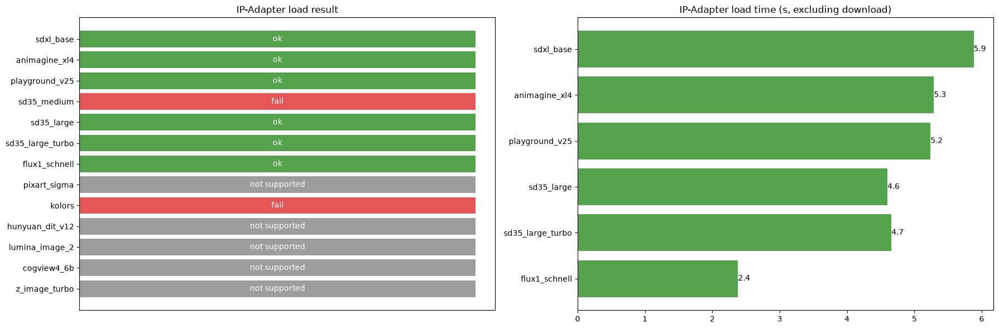

In [15]:
import matplotlib.pyplot as plt

# 같은 모델을 다시 시도하면 마지막 결과만 사용
ipa_df = pd.DataFrame(ipa_records).drop_duplicates('model', keep='last') if ipa_records else pd.DataFrame(columns=['model', 'ok'])
status = pd.DataFrame({'model': list(MODELS), 'ipa': [MODELS[m]['ipa'] for m in MODELS]}).merge(ipa_df, on=['model', 'ipa'], how='left')
status['status'] = [('not supported' if pd.isna(r.ipa) else 'not tried' if pd.isna(r.ok) else 'ok' if r.ok else 'fail')
                    for r in status.itertuples()]
status.to_csv(OUT_DIR / 'ipa_load_summary.csv', index=False, encoding='utf-8-sig')
display(status)

palette = {'ok': '#54A24B', 'fail': '#E45756', 'not supported': '#9D9D9D', 'not tried': '#F2CF5B'}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 6))
a1.barh(status['model'], 1, color=[palette[s] for s in status['status']])
for y, s in enumerate(status['status']):
    a1.text(0.5, y, s, ha='center', va='center', color='white', fontsize=10)
a1.invert_yaxis()
a1.set_xticks([])
a1.set_title('IP-Adapter load result')
ok = status[status['status'] == 'ok']
bars = a2.barh(ok['model'], ok['ipa_load_sec'], color='#54A24B')
a2.bar_label(bars, fmt='%.1f')
a2.invert_yaxis()
a2.set_title('IP-Adapter load time (s, excluding download)')
plt.tight_layout()
plt.savefig(OUT_DIR / 'ipa_load.png', dpi=100)
plt.show()

## 측정 항목 시각화

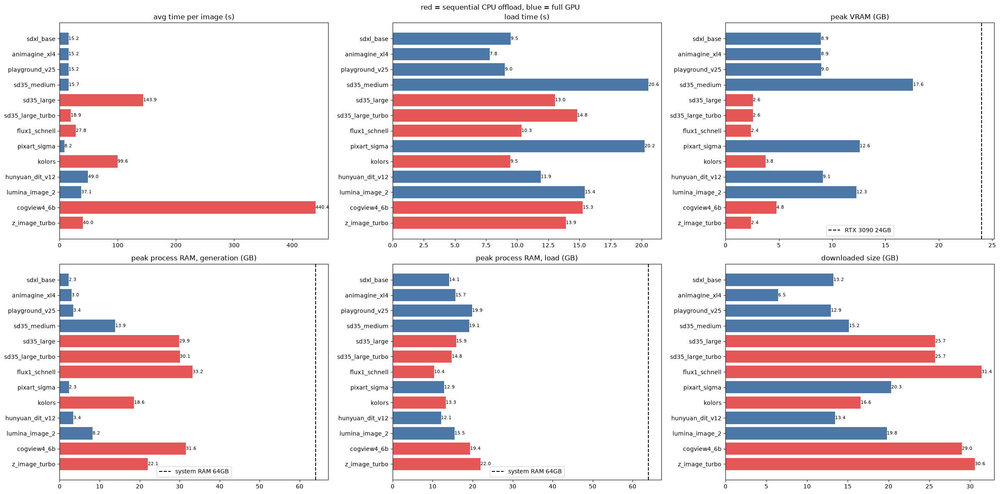

In [16]:
import matplotlib.pyplot as plt

# 오프로드 모델은 조건이 달라 색으로 구분 (속도는 같은 방식끼리만 비교)
colors = ['#E45756' if o else '#4C78A8' for o in summary['offload']]
metrics = [('avg_sec', 'avg time per image (s)'), ('load_sec', 'load time (s)'),
           ('max_vram_gb', 'peak VRAM (GB)'), ('max_ram_gb', 'peak process RAM, generation (GB)'),
           ('load_peak_ram_gb', 'peak process RAM, load (GB)'), ('download_gb', 'downloaded size (GB)')]
fig, axes = plt.subplots(2, 3, figsize=(24, 12))
for ax, (col, title) in zip(axes.flat, metrics):
    bars = ax.barh(summary.index, summary[col], color=colors)
    ax.bar_label(bars, fmt='%.1f', fontsize=8)
    ax.invert_yaxis()
    ax.set_title(title)
axes[0, 2].axvline(24, color='black', linestyle='--', label='RTX 3090 24GB')
axes[0, 2].legend()
for ax in (axes[1, 0], axes[1, 1]):
    ax.axvline(64, color='black', linestyle='--', label='system RAM 64GB')
    ax.legend()
fig.suptitle('red = sequential CPU offload, blue = full GPU')
plt.tight_layout()
plt.savefig(OUT_DIR / 'compare_bars.png', dpi=100)
plt.show()

## 생성 결과 그리드

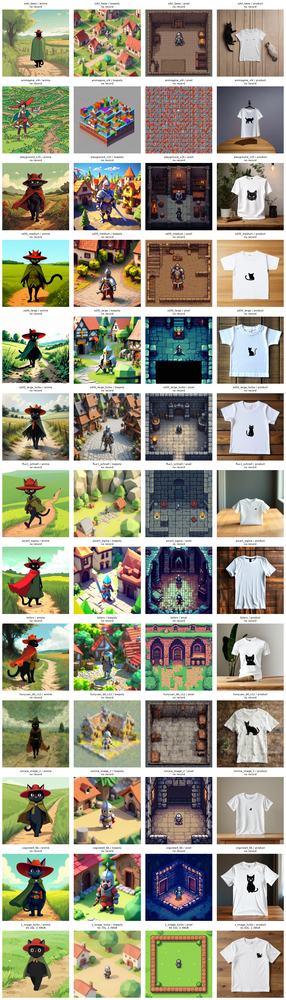

In [ ]:
# 모델 13 × (프롬프트 4 × seed 3)를 한 장에 넣으면 너무 커서 프롬프트별로 나눠 저장
for p in PROMPTS:
    model_names = [m for m in MODELS if any((m, p, s) in images for s in SEEDS)]
    if not model_names:
        continue
    fig, axes = plt.subplots(len(model_names), len(SEEDS), figsize=(3.2 * len(SEEDS), 3.6 * len(model_names)), squeeze=False)
    for i, m in enumerate(model_names):
        for j, s in enumerate(SEEDS):
            ax = axes[i, j]
            ax.axis('off')
            if (m, p, s) not in images:
                ax.set_title(f'{m} / s{s}\nFAIL', fontsize=8, color='red')
                continue
            ax.imshow(images[(m, p, s)])
            rows = df[(df.model == m) & (df.prompt == p) & (df.seed == s)]
            if rows.empty:
                ax.set_title(f'{m} / s{s}\nno record', fontsize=8)
                continue
            r = rows.iloc[0]
            ax.set_title(f'{m} / s{s}\n{r.sec}s, VRAM {r.peak_vram_gb}GB, RAM {r.peak_ram_gb}GB', fontsize=8)
    fig.suptitle(p)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'compare_grid_{p}.png', dpi=80)
    plt.show()